# Alpha Research Demo
This notebook runs the full multi-factor alpha pipeline.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from data_pipeline import load_prices, compute_returns, align_universe
from factor_engine import compute_momentum, compute_reversal, compute_volatility, combine_factors
from backtest import make_long_short_weights, compute_portfolio_returns, performance_stats
from risk_model import factor_correlation_matrix

In [5]:
prices = load_prices("../data/prices.csv")
prices = align_universe(prices, min_obs=3)
prices.head()

,AAPL,MSFT,GOOG
date,,,
2024-01-01,100,200,300
2024-01-02,101,202,298
2024-01-03,103,201,297
2024-01-04,104,205,295
2024-01-05,106,207,296


In [6]:
returns = compute_returns(prices)
returns.head()

,AAPL,MSFT,GOOG
date,,,
2024-01-01,NaN,NaN,NaN
2024-01-02,0.009950,0.009950,-0.006689
2024-01-03,0.019608,-0.004963,-0.003361
2024-01-04,0.009662,0.019705,-0.006757
2024-01-05,0.019048,0.009709,0.003384


In [7]:
mom = compute_momentum(prices, lookback=2)
rev = compute_reversal(returns, lag=1)
vol = compute_volatility(returns, window=3)

factor_dict = {"MOM": mom, "REV": rev, "VOL": vol}
combined = combine_factors(factor_dict)
combined.tail()

,AAPL,MSFT,GOOG
date,,,
2024-01-01,NaN,NaN,NaN
2024-01-02,NaN,NaN,NaN
2024-01-03,0.164957,-0.247436,0.082479
2024-01-04,-0.145852,0.627752,-0.481900
2024-01-05,-0.041699,0.279512,-0.237813


In [8]:
weights = make_long_short_weights(combined, long_quantile=0.5, short_quantile=0.5)
pf_returns = compute_portfolio_returns(weights, returns)
stats = performance_stats(pf_returns)
stats

{'mean_daily': -0.0010673237688459789,
 'vol_daily': 0.001836543331192337,
 'sharpe': -9.225613834838219,
 'cum_return': -0.005331972826769227,
 'max_drawdown': -0.005331972826769227}

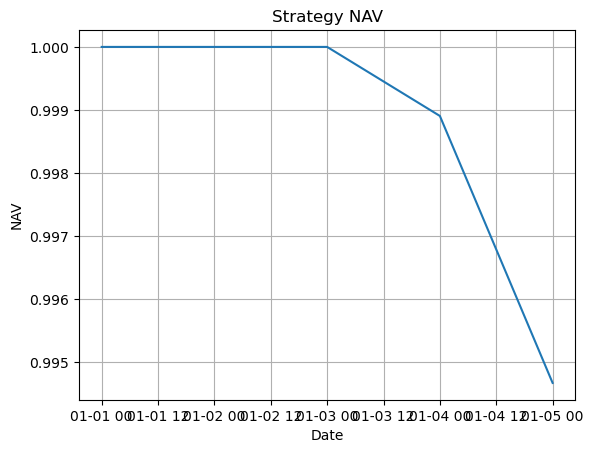

In [9]:
nav = (1 + pf_returns.fillna(0)).cumprod()
plt.plot(nav.index, nav.values)
plt.title("Strategy NAV")
plt.xlabel("Date")
plt.ylabel("NAV")
plt.grid(True)
plt.show()

In [10]:
corr = factor_correlation_matrix(factor_dict)
corr

,MOM,REV,VOL
MOM,1.0,NaN,NaN
REV,NaN,NaN,NaN
VOL,NaN,NaN,1.0
